# Forecast check: EWMA, GARCH, HAR, GBM and the VIX variant

Visual check of the three econometric baselines, the gradient boosting model and its
VIX-augmented variant against the realized volatility they are scored on, and the
head-to-head between them.
Run from the `notebooks/` folder, after `python -m data.download`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from evaluation.forecasts import evaluate_forecasts
from evaluation.run_forecasts import TWO_DAY_SUFFIX, two_day_names, load_forecasts, load_params
from models.gbm import FEATURES, GradientBoosting
from models.gbm_vix import FEATURES as VIX_FEATURES
from models.gbm_vix import GradientBoostingVIX

COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "green": "#3f8f5b", "purple": "#8657b5",
          "red": "#b5453a", "ink": "#0b0b0b", "muted": "#898781", "grid": "#e1e0d9"}
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "text.color": COLORS["ink"], "axes.titlecolor": COLORS["ink"],
    "axes.prop_cycle": plt.cycler(color=[COLORS["blue"], COLORS["orange"]]),
})

MODELS = ["ewma", "garch", "har", "gbm", "gbm_vix"]
MODEL_COLORS = [COLORS["blue"], COLORS["orange"], COLORS["green"], COLORS["purple"], COLORS["red"]]
ANN = np.sqrt(252)
df = pd.read_parquet(Path("../data/cache/spy_dataset.parquet"))
print(df.shape, df.index[0].date(), "->", df.index[-1].date())

(6661, 11) 2000-01-04 -> 2026-06-30


## Walk-forward

The forecasts come from `evaluation/walk_forward.py`, the loop the backtester runs
too, so both halves of the thesis score the same numbers: expanding window, monthly
refit, the fixed sequence - `update(t)`, then `fit(df up to t)` on the last
trading day of the month, then `predict()`. Each forecast is stored under the day it
forecasts rather than the day it was made, which is the alignment everything else
depends on.

`python -m evaluation.run_forecasts` runs it once for every model and caches the
result under `data/cache/forecasts/`, next to a manifest recording the training cut
and the checksums of the raw snapshot behind it. This notebook loads that cache, so
the figures below and the thesis tables are the same run rather than two runs that
happen to agree.

In [2]:
pair = load_forecasts().assign(realized=df["realized_vol_gk"]).dropna()
garch_params, har_params, gbm_params, gbm_vix_params = (
    load_params(n) for n in ["garch", "har", "gbm", "gbm_vix"]
)
print(f"{len(pair)} forecasts, {pair.index[0].date()} to {pair.index[-1].date()}")

4147 forecasts, 2010-01-04 to 2026-06-30


## What the forecast is compared against

`predict()` returns a daily standard deviation, not annualized, for the day after the
last one ingested. The truth it is scored against is `realized_vol_gk` on that same
day - also a daily standard deviation, the Garman-Klass intraday term plus the squared
overnight gap.

Because the loop stores each forecast under the day it forecasts, the columns line
up directly: row t pairs the forecast made at the close of t-1 with what actually
happened on t. Getting this alignment wrong in either direction is the bug that would
silently flatter every model.

Annualizing (x sqrt(252)) is only to make the charts readable. QLIKE and RMSE are
computed on **variances** (both sides squared) inside the evaluation module, not here.

In [3]:
(pair.head() * ANN).style.format("{:.1%}")

,ewma,garch,har,gbm,gbm_vix,trailing,realized
date,,,,,,,
2010-01-04 00:00:00,12.1%,11.9%,9.9%,10.7%,14.8%,12.8%,21.3%
2010-01-05 00:00:00,13.5%,13.6%,13.7%,10.5%,12.1%,13.4%,7.6%
2010-01-06 00:00:00,13.1%,13.1%,12.5%,12.3%,13.7%,13.0%,5.5%
2010-01-07 00:00:00,12.7%,12.6%,12.0%,10.8%,11.8%,11.2%,10.1%
2010-01-08 00:00:00,12.4%,12.3%,12.3%,9.6%,12.6%,11.2%,8.5%


## EWMA

The forecast should sit inside the realized cloud and move with it. It is smooth by
construction: with lambda = 0.94 each day only moves the estimate by 6%, a half-life
of about 11 trading days.

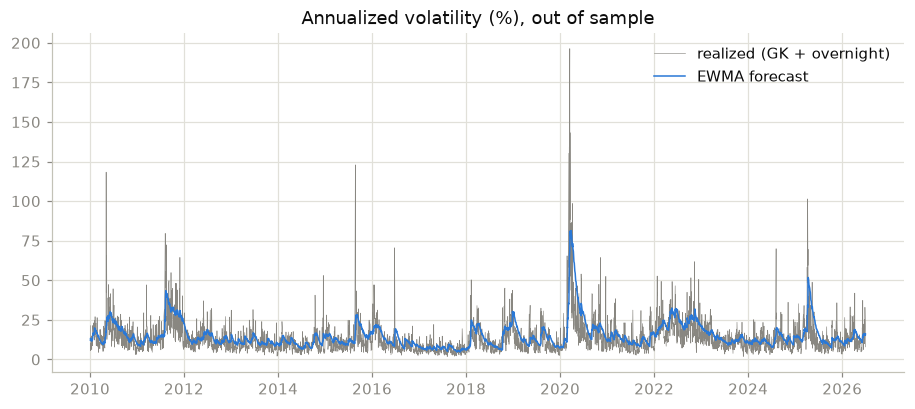

In [4]:
fig, ax = plt.subplots()
ax.plot(pair.index, pair["realized"] * ANN * 100, lw=0.4,
        color=COLORS["muted"], label="realized (GK + overnight)")
ax.plot(pair.index, pair["ewma"] * ANN * 100, lw=1.0,
        color=COLORS["blue"], label="EWMA forecast")
ax.set_title("Annualized volatility (%), out of sample")
ax.legend(frameon=False)
plt.show()

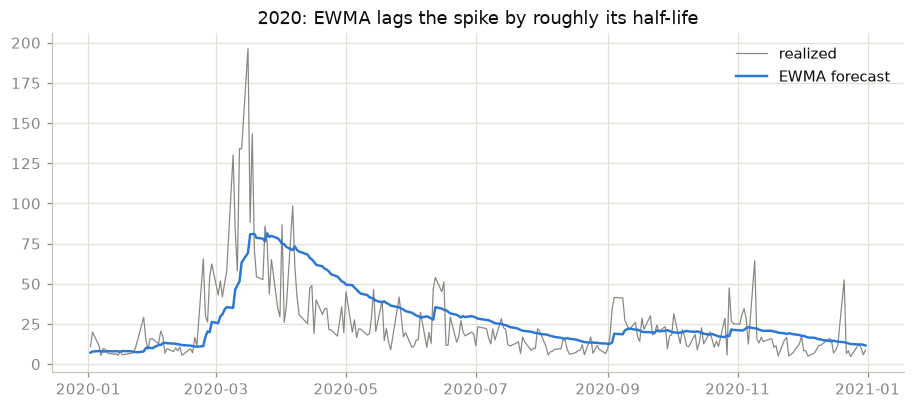

In [5]:
zoom = pair.loc["2020"]
fig, ax = plt.subplots()
ax.plot(zoom.index, zoom["realized"] * ANN * 100, lw=0.8,
        color=COLORS["muted"], label="realized")
ax.plot(zoom.index, zoom["ewma"] * ANN * 100, lw=1.6,
        color=COLORS["blue"], label="EWMA forecast")
ax.set_title("2020: EWMA lags the spike by roughly its half-life")
ax.legend(frameon=False)
plt.show()

## The target is deliberately noisy

A single day's realized estimate is a very noisy read on that day's true volatility,
so the grey line will never be tracked point by point - and it is not supposed to be.
The target is the raw one-day estimate (Patton 2011: QLIKE and MSE are
robust to a noisy but unbiased proxy; smoothing it would leak information across days
and distort the model ranking).

To show the noise lives in the proxy rather than in the model, score the same forecasts
against a 22-day window **centred** on the target day: that strips measurement noise
without moving the horizon, and the log-variance correlation goes from 0.61 to 0.83.
A forward window does not help, because it removes noise and pushes the target further
out at the same time; a trailing window is near-tautological, since EWMA is itself close
to a weighted trailing average. These smoothed targets peek ahead deliberately and are
diagnostics only - nothing here feeds the thesis metrics, where the target is the raw
one-day estimate.

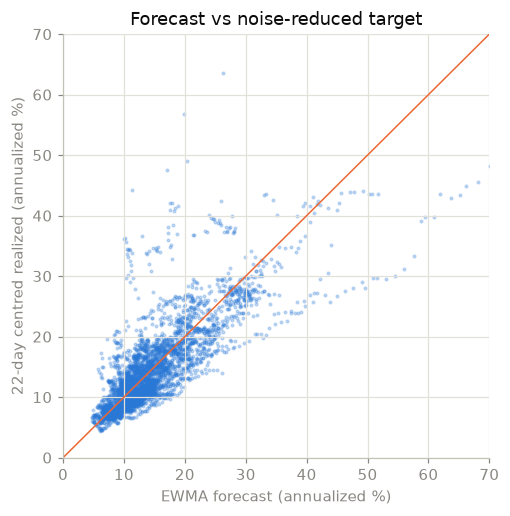

log-variance correlation vs one-day (the real target) : 0.614
log-variance correlation vs 22-day centred            : 0.832
log-variance correlation vs 22-day forward            : 0.611


In [6]:
variance = pair["realized"] ** 2
centred = variance.rolling(22, center=True).mean() ** 0.5
diag = pd.DataFrame({"forecast": pair["ewma"], "centred": centred}).dropna()

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(diag["forecast"] * ANN * 100, diag["centred"] * ANN * 100,
           s=3, alpha=0.25, color=COLORS["blue"])
lim = [0, 70]
ax.plot(lim, lim, lw=1, color=COLORS["orange"])
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("EWMA forecast (annualized %)")
ax.set_ylabel("22-day centred realized (annualized %)")
ax.set_title("Forecast vs noise-reduced target")
plt.show()

targets = {
    "one-day (the real target)": pair["realized"],
    "22-day centred": centred,
    "22-day forward": variance.rolling(22).mean().shift(-21) ** 0.5,
}
for label, target in targets.items():
    both = pd.DataFrame({"f": pair["ewma"], "t": target}).dropna()
    r = np.corrcoef(np.log(both["f"] ** 2), np.log(both["t"] ** 2))[0, 1]
    print(f"log-variance correlation vs {label:<26}: {r:.3f}")

## GARCH

Same recursion shape as EWMA - today's variance is a weighted mix of yesterday's
variance and yesterday's squared shock - but the weights are estimated instead of
fixed, and there is a constant term that pulls the forecast back towards a long-run
level. That third term is the whole difference: EWMA has no mean reversion, so it drifts
wherever the last shocks push it.

Two things to check on the estimated coefficients across the 197 refits.

Persistence, alpha + beta, sits just under 1 (mean 0.997). The process is stationary, so
the long-run variance omega / (1 - alpha - beta) exists, but it is approached so slowly
that reversion is only visible over months. EWMA is the alpha + beta = 1 corner of this
same family, which is why the two forecasts correlate at 0.96.

The Student-t degrees of freedom settle around 6.8, far from the 30-plus where the t is
indistinguishable from a normal. Daily equity shocks are genuinely fat-tailed, and a
Gaussian likelihood would absorb that by inflating the variance estimates instead.

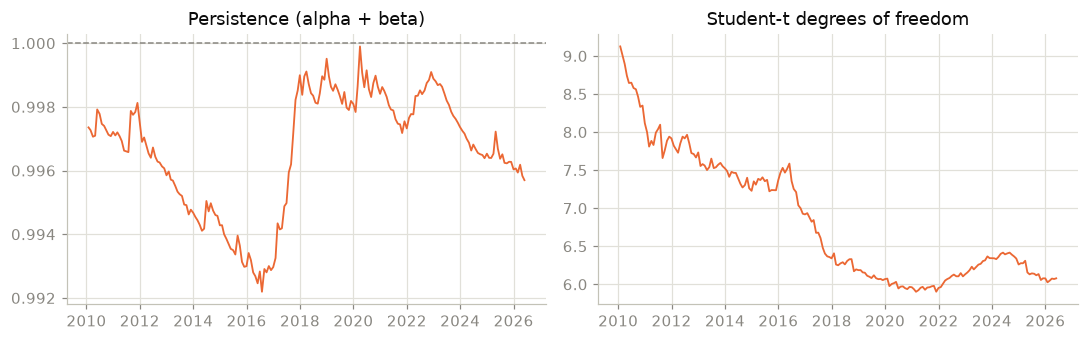

,mean,std,min,max
mu,0.0774,0.0085,0.0537,0.0902
omega,0.0128,0.0022,0.0077,0.0162
alpha[1],0.1111,0.0176,0.0787,0.1354
beta[1],0.8856,0.0169,0.8622,0.9187
nu,6.8334,0.8200,5.9025,9.1249


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(garch_params.index, garch_params["alpha[1]"] + garch_params["beta[1]"],
             lw=1.2, color=COLORS["orange"])
axes[0].axhline(1.0, lw=1, ls="--", color=COLORS["muted"])
axes[0].set_title("Persistence (alpha + beta)")
axes[1].plot(garch_params.index, garch_params["nu"], lw=1.2, color=COLORS["orange"])
axes[1].set_title("Student-t degrees of freedom")
plt.tight_layout()
plt.show()

garch_params.describe().loc[["mean", "std", "min", "max"]].T.style.format("{:.4f}")

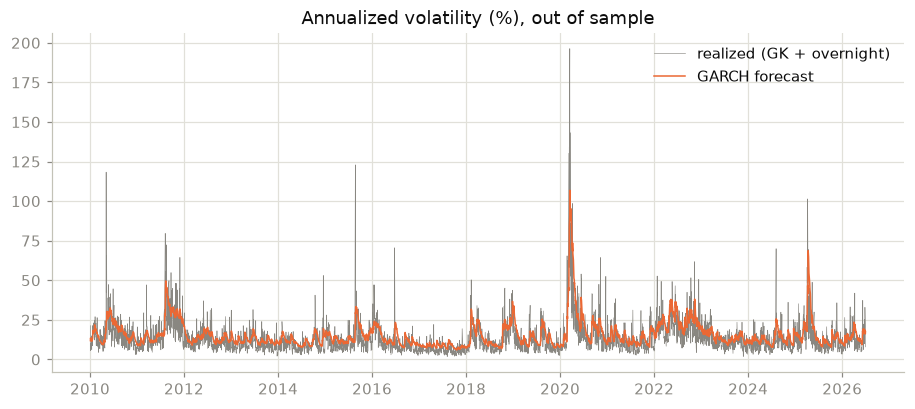

In [8]:
fig, ax = plt.subplots()
ax.plot(pair.index, pair["realized"] * ANN * 100, lw=0.4,
        color=COLORS["muted"], label="realized (GK + overnight)")
ax.plot(pair.index, pair["garch"] * ANN * 100, lw=1.0,
        color=COLORS["orange"], label="GARCH forecast")
ax.set_title("Annualized volatility (%), out of sample")
ax.legend(frameon=False)
plt.show()

## HAR

The first model that does not run a recursion at all. It is an ordinary regression of
tomorrow's log variance on the log of the realized variance averaged over the last day,
the last week and the last month, all three windows ending on the day the forecast is
made. The story behind it is that traders act on different horizons and the slower ones
transmit volatility down to the faster ones; the practical point is that it reads the
realized estimator directly rather than inferring variance from squared returns.

The three slopes are stable across refits and rank the way the literature reports:
weekly largest (mean 0.44), monthly next (0.33), daily smallest (0.15). They sum to
about 0.92, so the fitted process mean-reverts noticeably faster than GARCH's 0.997.

Working in logs is what keeps the regression well behaved - variance is right-skewed
and strictly positive - but it means exponentiating the fitted value returns a median,
not a mean. `predict()` corrects that with half the residual variance, and that residual
variance is measured out of sample on the last fifth of the training window rather than
in sample, which is the same treatment the GBM will get.

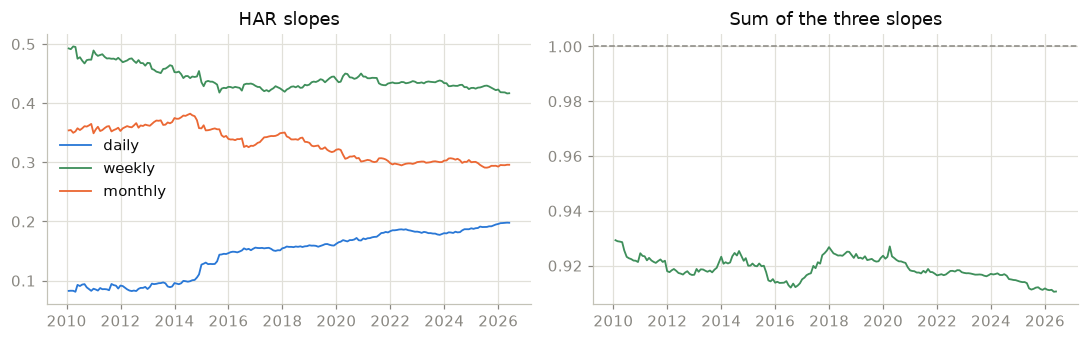

,mean,std,min,max
const,-0.9587,0.0437,-1.0506,-0.8332
daily,0.1451,0.0388,0.0812,0.1981
weekly,0.4425,0.0189,0.4165,0.4959
monthly,0.3314,0.0274,0.2910,0.3822


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for name, color in zip(["daily", "weekly", "monthly"],
                       [COLORS["blue"], COLORS["green"], COLORS["orange"]]):
    axes[0].plot(har_params.index, har_params[name], lw=1.2, color=color, label=name)
axes[0].legend(frameon=False)
axes[0].set_title("HAR slopes")
axes[1].plot(har_params.index, har_params[["daily", "weekly", "monthly"]].sum(axis=1),
             lw=1.2, color=COLORS["green"])
axes[1].axhline(1.0, lw=1, ls="--", color=COLORS["muted"])
axes[1].set_title("Sum of the three slopes")
plt.tight_layout()
plt.show()

har_params.describe().loc[["mean", "std", "min", "max"]].T.style.format("{:.4f}")

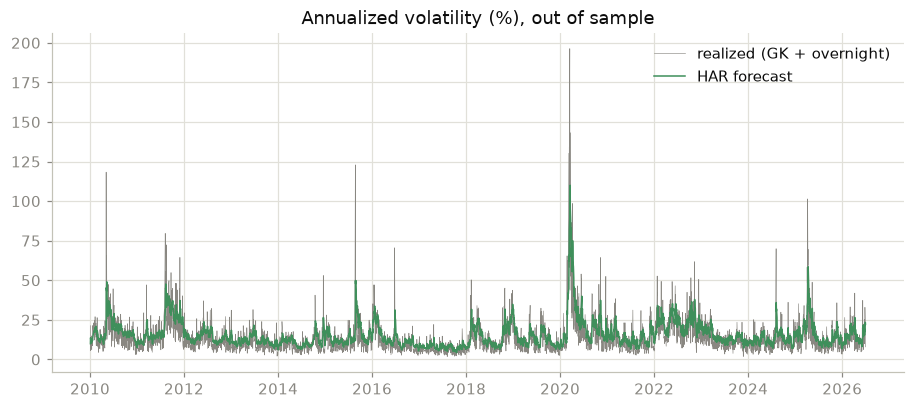

In [10]:
fig, ax = plt.subplots()
ax.plot(pair.index, pair["realized"] * ANN * 100, lw=0.4,
        color=COLORS["muted"], label="realized (GK + overnight)")
ax.plot(pair.index, pair["har"] * ANN * 100, lw=1.0,
        color=COLORS["green"], label="HAR forecast")
ax.set_title("Annualized volatility (%), out of sample")
ax.legend(frameon=False)
plt.show()

## Gradient boosting

The fourth model keeps the HAR's information and drops its functional form: LightGBM
on nine features - the three HAR means, so the HAR's regressors are nested exactly,
plus the previous day's log variance, the signed daily return and its 5 and 22 day
sums, the downside semivariance and the Parkinson range. The set is the survivor of a
validation-scored trim of a wider literature battery (more daily lags, upside
semivariance, a spike ratio, the overnight share, higher moments, candle shape):
features were ranked by average gain, nested subsets were compared on mean validation
error across all refits, never on the out-of-sample window, and the smallest set won.
Each refit re-tunes learning rate and num_leaves on a chronological 80/20 split with a
22-day embargo, takes the tree count from early stopping, then refits on the full
window with that count; the lognormal correction is estimated on the same validation
slice the HAR uses.

Three health checks across the refits: the chosen hyperparameters should move around
the grid without piling onto one corner, the tree count should stay far from the 2000
cap, and the importance ranking should be led by the variance features.

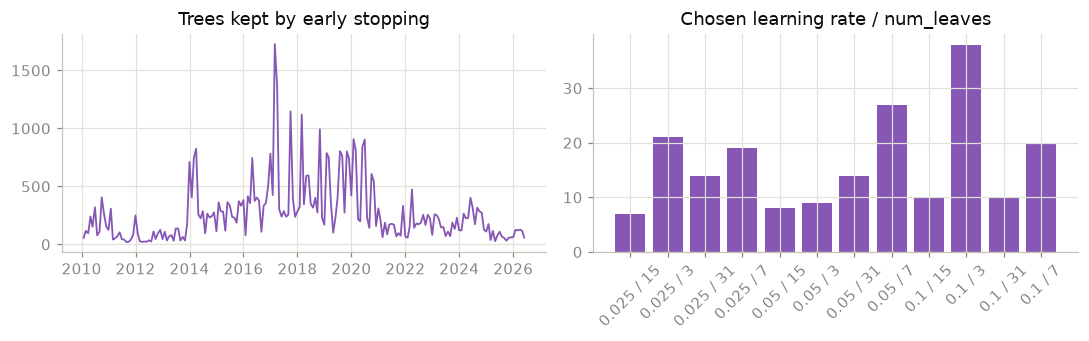

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(gbm_params.index, gbm_params["trees"], lw=1.2, color=COLORS["purple"])
axes[0].set_title("Trees kept by early stopping")
combos = (gbm_params["learning_rate"].astype(str) + " / "
          + gbm_params["num_leaves"].astype(int).astype(str))
counts = combos.value_counts().sort_index()
axes[1].bar(counts.index, counts.to_numpy(), color=COLORS["purple"])
axes[1].set_title("Chosen learning rate / num_leaves")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

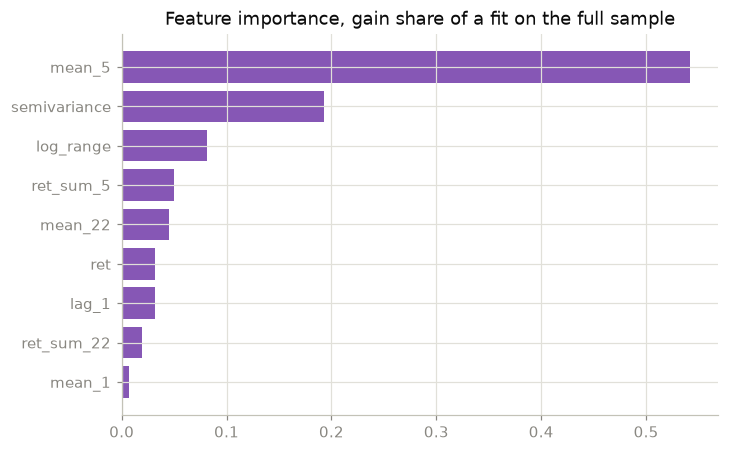

In [12]:
fitted = GradientBoosting()
fitted.fit(df)
importance = pd.Series(fitted.model.feature_importance("gain"), index=FEATURES)
importance = (importance / importance.sum()).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index, importance.to_numpy(), color=COLORS["purple"])
ax.set_title("Feature importance, gain share of a fit on the full sample")
plt.show()

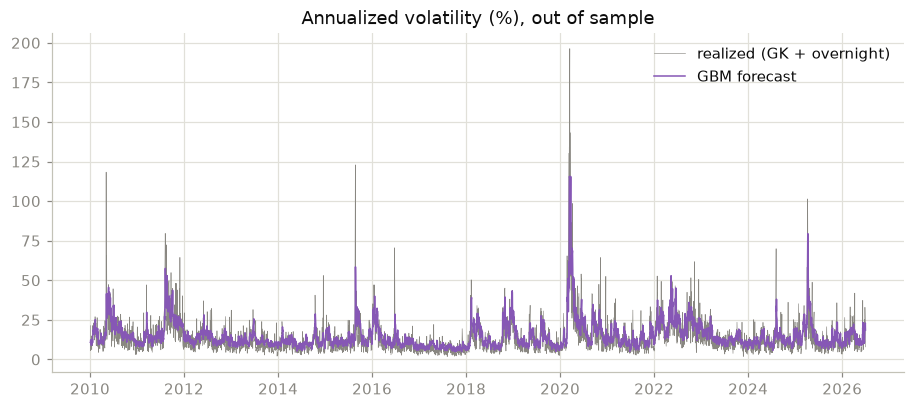

In [13]:
fig, ax = plt.subplots()
ax.plot(pair.index, pair["realized"] * ANN * 100, lw=0.4,
        color=COLORS["muted"], label="realized (GK + overnight)")
ax.plot(pair.index, pair["gbm"] * ANN * 100, lw=1.0,
        color=COLORS["purple"], label="GBM forecast")
ax.set_title("Annualized volatility (%), out of sample")
ax.legend(frameon=False)
plt.show()

## Gradient boosting with the VIX

The fifth model is the same LightGBM under the same protocol - same grid, same embargo,
same lognormal correction, same walk-forward - with three predictors added, so any
difference against the base GBM comes from the information and not from the fitting.
The three are the VIX quote rewritten as a log daily variance, on the same scale as the
other volatility features; its daily change, which is stationary where the level is not;
and the variance risk premium, the VIX variance minus the realized variance of the day,
the one quantity in the set that no other model can see.

This is the extension pre-registered as a stretch goal. It matters that it was
specified before any of these numbers existed: the feature set was not chosen by looking
at the table below.

The VIX has full history over the sample, so this variant runs on the main sample and
sits in the same table as the other four. TLT and HYG were left out on purpose - HYG only
trades from mid-2007, which would force the common-sample rule and cut the first training
window from ten years to under three.


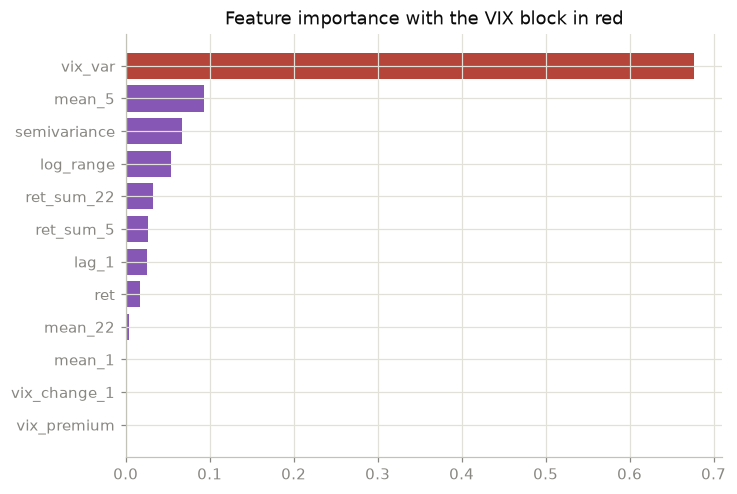

VIX features take 67.9% of the total gain


In [14]:
fitted_vix = GradientBoostingVIX()
fitted_vix.fit(df)
importance = pd.Series(fitted_vix.model.feature_importance("gain"), index=VIX_FEATURES)
importance = (importance / importance.sum()).sort_values()
colors = [COLORS["red"] if name.startswith("vix_") else COLORS["purple"]
          for name in importance.index]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance.index, importance.to_numpy(), color=colors)
ax.set_title("Feature importance with the VIX block in red")
plt.show()

print(f"VIX features take {importance[list(importance.index.str.startswith('vix_'))].sum():.1%}"
      " of the total gain")

The importance plot is the health check: three of twelve features take about two thirds
of the total gain, so the model leans hard on the VIX block rather than treating it as a
marginal addition. That is the expected shape - implied volatility is a direct read on
tomorrow's variance - and it is also why the variant is reported separately rather than
replacing the base GBM, whose features use SPY alone.


## Head to head

The five lines are hard to tell apart most of the time, which is the point: all of them
are slow-moving weighted averages of the recent past. They part company at turning
points. In 2020 GARCH climbs faster than EWMA into the crash, because the estimated
alpha of about 0.11 is nearly double EWMA's fixed 0.06 weight on the newest shock, and
it comes down faster afterwards, because the constant term pulls it back while EWMA has
nothing pulling it anywhere. HAR and the two GBMs are the jumpiest, since they read the
realized estimator directly instead of filtering squared returns; the base GBM tracks
HAR closely and pulls away from it mostly on quiet days. The VIX variant is the one that
moves ahead of the others into the crash, which is what an implied-volatility predictor
is supposed to buy.

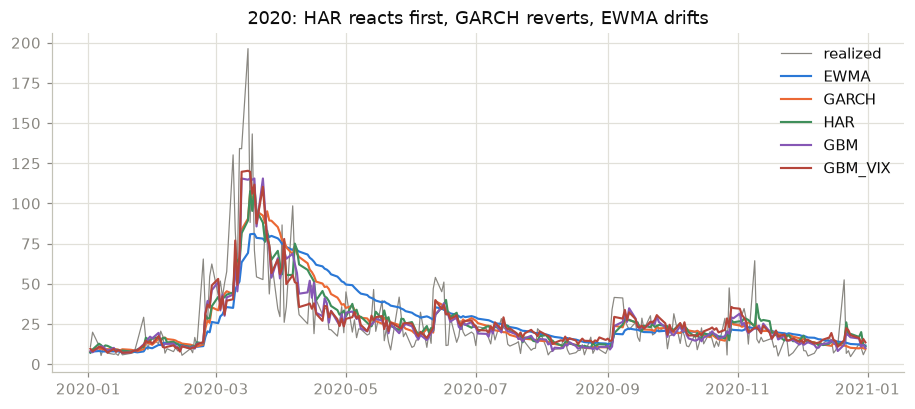

          ewma  garch    har    gbm  gbm_vix
ewma     1.000  0.959  0.904  0.839    0.816
garch    0.959  1.000  0.945  0.903    0.881
har      0.904  0.945  1.000  0.938    0.917
gbm      0.839  0.903  0.938  1.000    0.975
gbm_vix  0.816  0.881  0.917  0.975    1.000


In [15]:
zoom = pair.loc["2020"]
fig, ax = plt.subplots()
ax.plot(zoom.index, zoom["realized"] * ANN * 100, lw=0.8,
        color=COLORS["muted"], label="realized")
for name, color in zip(MODELS, MODEL_COLORS):
    ax.plot(zoom.index, zoom[name] * ANN * 100, lw=1.4, color=color, label=name.upper())
ax.set_title("2020: HAR reacts first, GARCH reverts, EWMA drifts")
ax.legend(frameon=False)
plt.show()

print(pair[MODELS].corr().round(3).to_string())

### Bias

All five should be unbiased in variance: mean forecast variance over mean realized
variance close to 1. Mean volatility runs higher than the median in every column because
the distribution is right-skewed; the gap is wider in the realized column, since
smoothing narrows it rather than causing it.

In [16]:
ratio = (pair[MODELS] ** 2).mean() / (pair["realized"] ** 2).mean()
print("mean forecast variance / mean realized variance")
print(ratio.round(3).to_string())

summary = pd.DataFrame({
    col: [pair[col].mean() * ANN, pair[col].median() * ANN,
          pair[col].min() * ANN, pair[col].max() * ANN]
    for col in MODELS + ["realized"]
}, index=["mean", "median", "min", "max"])
summary.style.format("{:.1%}")

mean forecast variance / mean realized variance
ewma       0.971
garch      1.037
har        1.012
gbm        0.996
gbm_vix    0.990


,ewma,garch,har,gbm,gbm_vix,realized
mean,15.0%,15.5%,15.4%,15.0%,15.0%,13.6%
median,12.7%,13.1%,13.3%,12.5%,12.7%,11.0%
min,4.7%,5.9%,4.2%,4.8%,4.4%,1.8%
max,81.4%,106.8%,110.0%,115.5%,120.3%,196.3%


### Scores

QLIKE is the headline metric, RMSE the secondary one, both on variances, both from
`evaluation/forecasts.py` so the numbers here are the same ones the thesis tables will
carry. The Diebold-Mariano column tests the QLIKE loss differential of each model
against the GBM, the comparison H1 fixes.

The second table repeats the exercise against absolute close-to-close returns, the
alternative unbiased proxy fixed for the robustness check. The levels are not
comparable across proxies and are not meant to be; what matters is that the ranking does
not move. `proxy_floored_days` counts days where the proxy variance sat at or below
1e-8: none under the GK target, 58 under the return proxy, of which 12 are exactly-zero
returns and the rest moves under one basis point.

The two realized-utility columns follow Bollerslev, Hood, Huss and Pedersen (2018): a
mean-variance investor with risk aversion 2 sizes a position in an asset with a constant
Sharpe ratio of 0.4 using each model's forecast, and the utility they realize depends only
on the ratio of realized to forecast volatility. A perfect forecast is worth 4% of wealth
per year; `realized_utility_share` is the fraction of that ceiling each model captures.
It is descriptive: it scores the square root of the proxy, which is not robust to proxy
noise the way QLIKE is, so QLIKE keeps the inference and this column gives the economic
scale of the gaps.

In [17]:
forecasts = {name: pair[name] for name in MODELS}
alt_proxy = df["log_ret"].abs().reindex(pair.index)
print("GK + overnight proxy")
print(evaluate_forecasts(forecasts, pair["realized"], benchmark="gbm").to_string())
print("\nabsolute return proxy")
print(evaluate_forecasts(forecasts, alt_proxy, benchmark="gbm").to_string())

GK + overnight proxy
            qlike      rmse  realized_utility  realized_utility_share  forecast_floored_days  proxy_floored_days   dm_stat     dm_pvalue
model                                                                                                                                   
ewma     0.497126  0.000363          0.029669                0.741731                      0                   0  8.125980  4.437619e-16
garch    0.443508  0.000338          0.031312                0.782806                      0                   0  7.979669  1.467264e-15
har      0.419195  0.000335          0.031748                0.793708                      0                   0  4.476793  7.577262e-06
gbm      0.378549  0.000303          0.032239                0.805975                      0                   0       NaN           NaN
gbm_vix  0.351995  0.000297          0.032938                0.823456                      0                   0 -4.742258  2.113491e-06

absolute return pro

The VIX variant wins on both metrics under both proxies, the base GBM is second, then
HAR, GARCH and EWMA, and the gaps are not noise: against the base GBM the DM statistics
are about 4.5 for HAR and about 8 for GARCH and EWMA, and about -4.7 for the VIX variant,
the negative sign meaning it beats the benchmark. All are comfortably significant with
Newey-West standard errors, and the ordering is identical under the absolute-return
proxy, which is what the robustness check asks for.

Two different things produce those two gaps. The base GBM's edge over HAR is pure
functional form: it nests the HAR's three regressors exactly, so it sees nothing HAR does
not. The VIX variant's edge over the base GBM is pure information, since the protocol is
identical and only the predictor matrix changes. Of the two, functional form is the larger
gap: 0.041 of QLIKE from HAR to the base GBM against 0.027 from the base GBM to the
VIX variant. The DM statistics, 4.5 and 4.7, say only that neither gap is noise, not
how big it is.

Splitting by realized volatility shows where each gap lives, and they sit in opposite
places. The base GBM leads by a wide margin on the calm half and only a modest one on the
turbulent half, where HAR and GARCH bunch together and EWMA falls apart: trees cannot
extrapolate beyond the variance levels they saw in training, so crises are ridden mostly
on the same lagged-variance level every model tracks, and the fine structure of quiet
markets is where flexibility earns its keep. The VIX variant reverses that. Its gain over
the base GBM is small on the calm half and large on the turbulent one, which is exactly
what a forward-looking predictor should buy: it fixes the regime where lagged realized
variance has least to say.

That turns out to matter for the thesis in an awkward way. The strategy caps leverage at
1.5x, and the weight is target vol over forecast vol, a function that is flat precisely
where the VIX variant gains most - high volatility, where the weight is already small.
The statistical gap and the economic gap need not line up, and here the largest part of
the statistical gain lands where the portfolio has the least at stake. Whether it
survives into the strategy is the backtester's question, not this notebook's.

Realized utility reproduces the QLIKE order exactly and puts a wealth scale on it: the VIX
variant captures 82% of the perfect-forecast ceiling, the base GBM 81%, HAR 79%, GARCH 78%
and EWMA 74%. From EWMA to the VIX variant is 0.3% of wealth per year, and from HAR to
the base GBM 0.05%. Under the absolute-return proxy the
shares roughly halve, which is the proxy's noise entering the square root, and the order
still holds. Large and significant in QLIKE, the gaps are small in the currency a
volatility-targeting investor cares about, which is the same conclusion the backtester
reaches from the other side.

### Horizon and the execution lag

The backtest decides the weight with the close of t, trades at the close of t+1 and
earns the return of t+2, so the one-day forecast sizes a return one day after the day it
was made for. Everything here is indexed by the return day. `headline` is the one-day
forecast made the evening before, the score above. `stale` is the same forecast made one
day earlier, the one the weight actually carries into that return; the persistence of
daily variance, printed as the autocorrelation of log variance, is what keeps its loss
small. `two_day` is the forecast made on the decision day for the return day, cached
under the `_h2` suffix: HAR and both GBMs retrained with the target two days ahead, the
direct multi-step regression of Corsi (2009), GARCH iterating its recursion one step,
EWMA and trailing repeating their one-day forecast because it is flat across horizons.
The `dm_stat` columns test each model against the GBM of the same column; `dm_vs_stale`
tests each two-day forecast against its own stale one-day forecast, negative when the
two-day forecast loses less. `recovered` is the share of the stale loss the two-day
forecast wins back. The strategy side lives in the strategy notebook.

In [18]:
two_day = load_forecasts(two_day_names(MODELS)).rename(
    columns=lambda name: name.removesuffix(TWO_DAY_SUFFIX)
)
by_return_day = pd.concat(
    {"headline": pair[MODELS], "stale": pair[MODELS].shift(1), "two_day": two_day},
    axis=1,
)
by_return_day[("proxy", "realized")] = df["realized_vol_gk"].reindex(by_return_day.index)
by_return_day = by_return_day.dropna()
proxy = by_return_day[("proxy", "realized")]
scores = {
    column: evaluate_forecasts(
        {name: by_return_day[(column, name)] for name in MODELS}, proxy, benchmark="gbm"
    )
    for column in ("headline", "stale", "two_day")
}
horizon_table = pd.concat(
    {column: table[["qlike", "dm_stat", "dm_pvalue"]] for column, table in scores.items()},
    axis=1,
)
against_stale = {
    name: evaluate_forecasts(
        {"two_day": by_return_day[("two_day", name)], "stale": by_return_day[("stale", name)]},
        proxy,
        benchmark="stale",
    ).loc["two_day"]
    for name in MODELS
}
horizon_table[("two_day", "dm_vs_stale")] = pd.Series({k: v["dm_stat"] for k, v in against_stale.items()})
horizon_table[("two_day", "p_vs_stale")] = pd.Series({k: v["dm_pvalue"] for k, v in against_stale.items()})
stale_loss = horizon_table[("stale", "qlike")] - horizon_table[("headline", "qlike")]
horizon_table[("two_day", "recovered")] = (
    horizon_table[("stale", "qlike")] - horizon_table[("two_day", "qlike")]
) / stale_loss
log_variance = np.log(proxy**2)
print(f"{len(by_return_day)} return days")
print(f"log variance autocorrelation: lag 1 {log_variance.autocorr(1):.2f}, lag 2 {log_variance.autocorr(2):.2f}")
print(horizon_table.round(4).to_string())

4146 return days
log variance autocorrelation: lag 1 0.61, lag 2 0.59
        headline                     stale                   two_day                                                   
           qlike dm_stat dm_pvalue   qlike dm_stat dm_pvalue   qlike dm_stat dm_pvalue dm_vs_stale p_vs_stale recovered
model                                                                                                                  
ewma      0.4970  8.1387       0.0  0.5461  5.0351    0.0000  0.5461  5.3702    0.0000      0.0000     1.0000    0.0000
garch     0.4434  7.9958       0.0  0.4870  3.7658    0.0002  0.4856  5.1286    0.0000     -1.4766     0.1398    0.0302
har       0.4188  4.4640       0.0  0.4583  2.2358    0.0254  0.4537  2.8622    0.0042     -2.2734     0.0230    0.1177
gbm       0.3783     NaN       NaN  0.4399     NaN       NaN  0.4354     NaN       NaN     -0.7833     0.4335    0.0717
gbm_vix   0.3520 -4.6919       0.0  0.4098 -3.8952    0.0001  0.4067 -3.8141    0.0001    

The delay costs about 10% of QLIKE for EWMA, GARCH and HAR and about 16% for the two
GBMs, the fast-reacting models losing most of their edge from the stale day, the same
pattern the friction table shows going from lag 1 to lag 2. The ranking does not move
and every Diebold-Mariano against the GBM keeps its sign and its significance, HAR
narrowing to a statistic of 2.2. Training for the return day wins back little of that
loss, and only HAR's gain over its own stale forecast is significant. What the lag costs
is almost entirely the intrinsic loss of forecasting two days out, not an artefact of
training at the wrong horizon.

In [19]:
median = pair["realized"].median()
regimes = {"calm half": pair[pair["realized"] <= median],
           "turbulent half": pair[pair["realized"] > median]}
for label, sample in regimes.items():
    qlike = evaluate_forecasts(
        {name: sample[name] for name in MODELS}, sample["realized"]
    )["qlike"]
    print(f"{label:<16} " + "  ".join(f"{k}={v:.4f}" for k, v in qlike.items()))

calm half        ewma=0.4420  garch=0.4584  har=0.4294  gbm=0.3541  gbm_vix=0.3461
turbulent half   ewma=0.5523  garch=0.4286  har=0.4089  gbm=0.4030  gbm_vix=0.3579
